# ECE 5280 · Improved Battery Optimizer
### Exact convex state-of-charge model · LP relaxation · Worst-case robust dispatch

**Your assignment:** Convert a 24-hour electricity **price forecast** into a feasible 24-hour battery charge/discharge schedule. This notebook focuses on the optimization module. It **does not** train a price predictor; two simple lagged-price forecasts are used for integration tests until the price model is ready.

**What you will do:**

1. Understand how the battery model maps into an LP or MILP.
2. Run a small example with artificial prices and inspect the resulting charge, discharge, and state of charge.
3. Compare a **convex relaxation** with the paper's **exact SOC formulation** and an exact MILP.
4. Test *worst-case price uncertainty* instead of treating predicted prices as certain.
5. Run automated tests and backtest on the supplied chronological training CSV.
6. Export tables, plots, diagnostics, and code in a ZIP to share for the next round of improvements.

**Get started:** In Jupyter or VS Code, select a Python kernel and click **Run All**. Read the explanation above each code cell. If anything fails, save the traceback and send it with your results ZIP.

> **Sources:** ECE 4800/5280 Final Project (Fall 2026), §§2–5; F. Al Taha and E. Bitar, *When Are Lossy Energy Storage Optimization Models Convex?* (2024), Theorems 1–3 and Table I. Included in `references/`.

## 1 · Setup and editable trial settings

Change these settings and **Run All** again. `PRICE_RADII` is the assumed error bound in **$/MWh** around each forecast. The `2.5` in the assignment is **MWh per hour**, a completely different physical parameter.

The notebook defaults to 14 consecutive days near the end of the *released training CSV*, not the hidden validation/test set.

### Notebook plotting setup (macOS / Jupyter fix)

The last version forced Matplotlib's `Agg` backend inside `experiments.py`. That backend is intended for file saving, so `plt.show()` printed `FigureCanvasAgg is non-interactive` warnings. The new version **does not force Agg**. In a notebook, use the inline backend before imports:


In [1]:
%matplotlib inline
import matplotlib
print('Matplotlib notebook backend:', matplotlib.get_backend())


Matplotlib notebook backend: module://matplotlib_inline.backend_inline


In [2]:
from pathlib import Path
import sys, subprocess, json
import numpy as np
from IPython.display import display, Image
from optimizer import (
    T, CAPACITY, POWER, ETA_IN, ETA_OUT,
    optimize_lossless, optimize_lossy_soc_convex, optimize_lossy_milp,
    optimize_lossy_hybrid, optimize_lossy_relaxation,
    soc_objective_convex, stored_energy, check_schedule,
    realized_revenue, worst_case_revenue, solve_with_timing,
)
from experiments import (
    read_released_dataset, artificial_scenarios, export_all,
    RESULTS, FIGURES,
)
from pack_results import create_results_zip

ROOT = Path.cwd()
assert (ROOT / 'optimizer.py').exists(), 'Open Jupyter from the extracted ECE5280_Improved_Optimizer folder.'

# ===== EDIT THESE AND RE-RUN ALL CELLS =====
DAYS = 60                 # Length of sequential historical backtest
TRAIN_START = 250         # First day index (zero-based) in training_data.csv
PRICE_RADII = (0.0, 2.5, 10.0)    # Independent $/MWh worst-case intervals
FORECAST_BASELINES = ('yesterday', 'last_7_mean')
SAMPLE_INITIAL_ENERGY = 5.0        # MWh; battery starts full in a run
SAMPLE_ROBUST_RADIUS = 2.5        # $/MWh; illustration only
# ==========================================

print('Python:', sys.version.split()[0])
print('Battery:', CAPACITY, 'MWh; hourly power bound:', -POWER, 'to', POWER, 'MWh')
print('Lossy efficiencies:', ETA_IN, ETA_OUT)
print('Run settings:', DAYS, 'days, start at training day', TRAIN_START, 'radii', PRICE_RADII)

Python: 3.9.12
Battery: 5.0 MWh; hourly power bound: -2.5 to 2.5 MWh
Lossy efficiencies: 0.95 0.95
Run settings: 60 days, start at training day 250 radii (0.0, 2.5, 10.0)


## 2 · Understand the underlying optimization

The battery returns **grid energy exchange** `p[t]` in MWh. Positive means **buy electricity to charge**, negative means **sell electricity by discharging**.

| Course requirement | Value |
|---|---|
| 24 hourly decisions | $t=1,\dots,24$ |
| Grid exchange | $-2.5\le p_t\le2.5$ MWh |
| Stored battery energy | $0\le s_t\le5$ MWh |
| Lossy charging / discharging efficiencies | $\eta_{in}=\eta_{out}=0.95$ |
| Objective | Maximize $R=-\sum_t\lambda_t p_t$ |

### Lossless battery: a convex LP

$s_{t+1}=s_t+p_t$. Both the objective and constraints are linear. With **predicted** prices $\hat\lambda_t$, solve $\min_p\sum_t\hat\lambda_t p_t$.

### Lossy battery: exact state-of-charge transformation

The original dynamic equation contains `max(p,0)` and `min(p,0)`. **Do not replace `min(p,0)` by the numerical constant 2.5**; that would physically change the model. Instead let $\Delta_t=s_{t+1}-s_t$. The paper's inverse transformation is

$$
p_t=\begin{cases}\Delta_t/0.95,&\Delta_t\ge0,\\0.95\Delta_t,&\Delta_t<0.\end{cases}
$$

The **exact physical feasible set** becomes

$$0\le s_t\le5,\qquad -\frac{2.5}{0.95}\le\Delta_t\le(0.95)(2.5).$$

All these constraints are affine. No simultaneous charging/discharging is needed; `p` is reconstructed uniquely from $\Delta$. This is the exact convex **feasible set** from the paper (Theorems 1–2), **not merely a relaxation**.

## 3 · Add worst-case price uncertainty

Assume (as a modeling choice, **not** a provided course parameter) that each unknown DA price lies in the interval

$$\lambda_t\in[\hat\lambda_t-\rho_t,\hat\lambda_t+\rho_t],\qquad\rho_t\ge0.$$

For independent hourly price intervals, the **worst-case cost** of a fixed physical schedule is

$$\max_{\lambda}\sum_t\lambda_tp_t=\sum_t(\hat\lambda_tp_t+\rho_t|p_t|).$$

Therefore a robust scheduler **minimizes worst-case cost**, equivalently maximizes a worst-case revenue guarantee under the assumed intervals.

In the SOC variable $\Delta_t$, that cost is piecewise linear:

$$c_t(\Delta)=\begin{cases}a_t\Delta,&\Delta\ge0,\\b_t\Delta,&\Delta<0,\end{cases}\qquad a_t=\frac{\hat\lambda_t+\rho_t}{0.95},\quad b_t=0.95(\hat\lambda_t-\rho_t).$$

**Key theorem/application:** If $a_t\ge b_t$ for every hour, then $c_t(\Delta)=\max\{a_t\Delta,b_t\Delta\}$ is convex. An **exact linear-programming epigraph** adds variables $q_t$ and imposes

$$q_t\ge a_t\Delta_t,\quad q_t\ge b_t\Delta_t,\quad \min\sum_t q_t.$$

When the condition fails, `optimize_lossy_hybrid` falls back to the **exact mixed-integer linear program**, rather than treating an invalid relaxation as physical. With $\rho=0$, all nonnegative forecast prices satisfy the convexity condition; a sufficiently large $\rho$ can make some mildly negative forecast-price cases convex as well. A larger radius is **not automatically better** in realized revenue, and requires validation.

## 4 · First interactive experiment: artificial price patterns

**What to look for:** When prices are cheap, the optimizer prefers buying; when expensive, selling. The output is a full vector of 24 grid exchanges, plus 25 SOC values (including the initial state). All reported schedules are checked for physical feasibility.

In [3]:
scenarios = artificial_scenarios()
name = 'cheap_then_expensive'  # Try: flat_positive, negative_window, smooth_day
prices = scenarios[name]

nominal = solve_with_timing('lossy_hybrid', prices, SAMPLE_INITIAL_ENERGY, price_radius=0.0)
robust = solve_with_timing('lossy_hybrid', prices, SAMPLE_INITIAL_ENERGY, price_radius=SAMPLE_ROBUST_RADIUS)
lossless = solve_with_timing('lossless', prices, SAMPLE_INITIAL_ENERGY, price_radius=0.0)

for label, result, rho in [('Lossless', lossless, 0.0),
                           ('Lossy nominal',nominal,0.0),
                           ('Lossy robust',robust,SAMPLE_ROBUST_RADIUS)]:
    print(f"{label:14} method={result['method']:22}  "
          f"predicted revenue=${realized_revenue(prices,result['schedule']):.2f}  "
          f"worst-case revenue=${worst_case_revenue(prices,result['schedule'],rho):.2f}  "
          f"final SOC={result['soc'][-1]:.3f} MWh")

print('\nFirst eight hourly decisions (positive = charging, negative = discharging):')
print('hour  forecast $/MWh     nominal p     robust p')
for h in range(8):
    print(f'{h+1:>4}  {prices[h]:>14.2f}   {nominal["schedule"][h]:>11.4f}  {robust["schedule"][h]:>11.4f}')

Lossless       method=lossless_lp             predicted revenue=$475.00  worst-case revenue=$475.00  final SOC=0.000 MWh
Lossy nominal  method=exact_soc_convex_lp     predicted revenue=$451.25  worst-case revenue=$451.25  final SOC=0.000 MWh
Lossy robust   method=exact_soc_convex_lp     predicted revenue=$451.25  worst-case revenue=$439.38  final SOC=0.000 MWh

First eight hourly decisions (positive = charging, negative = discharging):
hour  forecast $/MWh     nominal p     robust p
   1           15.00       -0.0000       0.0000
   2           15.00        0.0000       0.0000
   3           15.00        0.0000       0.0000
   4           15.00        0.0000       0.0000
   5           15.00        0.0000       0.0000
   6           15.00        0.0000       0.0000
   7           15.00        0.0000      -0.0000
   8           15.00        0.0000      -0.0000


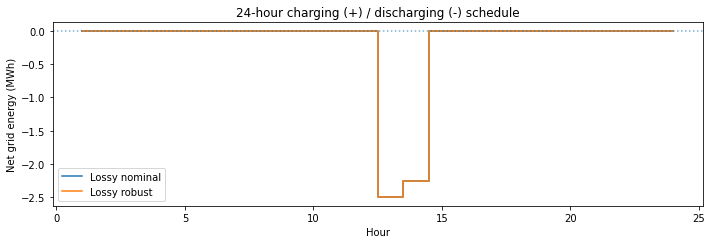

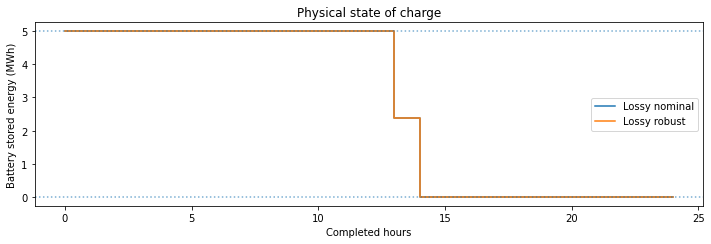

In [4]:
import matplotlib.pyplot as plt
hours = np.arange(1,25)
fig,ax = plt.subplots(figsize=(10,3.5))
ax.step(hours,nominal['schedule'],where='mid',label='Lossy nominal')
ax.step(hours,robust['schedule'],where='mid',label='Lossy robust')
ax.axhline(0,linestyle=':',alpha=.6)
ax.set(xlabel='Hour',ylabel='Net grid energy (MWh)',title='24-hour charging (+) / discharging (-) schedule')
ax.legend(); plt.tight_layout(); plt.show()

fig,ax=plt.subplots(figsize=(10,3.5))
ax.step(np.arange(25),nominal['soc'],where='post',label='Lossy nominal')
ax.step(np.arange(25),robust['soc'],where='post',label='Lossy robust')
ax.axhline(0,linestyle=':',alpha=.6);ax.axhline(5,linestyle=':',alpha=.6)
ax.set(xlabel='Completed hours',ylabel='Battery stored energy (MWh)',title='Physical state of charge')
ax.legend(); plt.tight_layout(); plt.show()

## 5 · Test the paper's convexity condition, including negative prices

The **feasible SOC set** is always convex. The **objective** only admits the exact convex LP when its branch slopes are ordered. Here is a negative-price example: the nominal SOC objective is nonconvex, but a ±$2.50/MWh robust interval can make it convex. We verify the SOC LP and the MILP achieve matching worst-case revenues.

In [5]:
example_prices = np.r_[np.full(10,-10.),np.full(14,40.)]
for radius in [0.,2.5]:
    a = (example_prices + radius)/ETA_IN
    b = (example_prices - radius)*ETA_OUT
    print(f'Radius ±${radius:.1f}: convex objective? {soc_objective_convex(example_prices,radius)}, '
          f'minimum slope margin a-b = {np.min(a-b):.5f}')
    hybrid,method=optimize_lossy_hybrid(example_prices,5.,price_radius=radius,return_method=True)
    print('    exact hybrid method =',method)
    if soc_objective_convex(example_prices,radius):
        soc_lp=optimize_lossy_soc_convex(example_prices,5.,price_radius=radius)
        milp=optimize_lossy_milp(example_prices,5.,price_radius=radius)
        gap=abs(worst_case_revenue(example_prices,soc_lp,radius)-
                worst_case_revenue(example_prices,milp,radius))
        print('    SOC LP vs. MILP worst-case revenue difference =',round(gap,7),'dollars')
        assert gap < 1e-4

Radius ±$0.0: convex objective? False, minimum slope margin a-b = -1.02632
    exact hybrid method = exact_milp_fallback
Radius ±$2.5: convex objective? True, minimum slope margin a-b = 3.98026
    exact hybrid method = exact_soc_convex_lp
    SOC LP vs. MILP worst-case revenue difference = 0.0 dollars


## 6 · Why a conventional convex LP relaxation can fail

A common *relaxation* introduces independent nonnegative charging and discharging variables, $c_t,d_t\ge0$, with

$$p_t=c_t-d_t,\qquad s_{t+1}=s_t+0.95c_t-d_t/0.95.$$

Without the **nonconvex complementarity** restriction $c_td_t=0$, the LP may charge and discharge **at the same time**. This can make its simulated state of charge differ from what the assignment's physical model would produce for the returned net power $p$.

**We intentionally stress-test** a full battery and 24 hours of negative prices. The result below is a diagnostic, not a proposed schedule for Gradescope. The exact SOC LP is preferred when valid; otherwise use the MILP.

In [6]:
negative_prices = np.full(24,-100.0)
relaxed = optimize_lossy_relaxation(negative_prices,5.)
exact, exact_method = optimize_lossy_hybrid(negative_prices,5.,return_method=True)
print('Convex split-LP relaxation:')
print('  Total simultaneous charge/discharge (sum min(c,d)) =',round(relaxed.simultaneous_energy,5),'MWh')
print('  Physical model agrees with LP SOC? ',relaxed.physically_exact)
print('  LP-model ending SOC:',round(float(relaxed.model_soc[-1]),5), 'MWh')
print('  Physical ending SOC from net power:',round(float(relaxed.physical_soc[-1]),5), 'MWh')
print('  Relaxed worst-case objective:',round(relaxed.relaxed_worst_cost,3), 'dollars cost')
print('Exact hybrid method:',exact_method)
print('  True worst-case revenue:',round(worst_case_revenue(negative_prices,exact),3),'dollars')
check_schedule(exact,5.,lossy=True)
assert not relaxed.physically_exact  # deliberate stress test of unsafe relaxation

Convex split-LP relaxation:
  Total simultaneous charge/discharge (sum min(c,d)) = 54.15 MWh
  Physical model agrees with LP SOC?  False
  LP-model ending SOC: 5.0 MWh
  Physical ending SOC from net power: 10.5575 MWh
  Relaxed worst-case objective: -585.0 dollars cost
Exact hybrid method: exact_milp_fallback
  True worst-case revenue: 297.091 dollars


## 7 · Automated correctness tests

The test suite checks capacity and power limits, SOC inversion, positive/negative price cases, **matching optimal cost from exact SOC LP and exact MILP**, robust slope conditions, and an intentionally infeasible relaxation example. Any failed assertion should be preserved in your results ZIP.

In [7]:
test_run = subprocess.run([sys.executable, '-m','unittest','-v','test_optimizer.py'],
                          cwd=ROOT,text=True,stdout=subprocess.PIPE,
                          stderr=subprocess.STDOUT,timeout=120)
RESULTS.mkdir(parents=True,exist_ok=True)
(RESULTS/'unit_tests.txt').write_text(test_run.stdout,encoding='utf-8')
print(test_run.stdout)
if test_run.returncode:
    raise RuntimeError('Unit tests failed. Please share unit_tests.txt and error output for debugging.')

test_both_edges_and_signs (test_optimizer.OptimizerTests) ... ok
test_final_day_no_salvage_credit (test_optimizer.OptimizerTests) ... ok
test_hybrid_negative_fallback (test_optimizer.OptimizerTests) ... ok
test_idle (test_optimizer.OptimizerTests) ... ok
test_lossless_mixed_prices (test_optimizer.OptimizerTests) ... ok
test_model_constants (test_optimizer.OptimizerTests) ... ok
test_negative_prices_with_robust_convexification (test_optimizer.OptimizerTests) ... ok
test_no_leakage_signature (test_optimizer.OptimizerTests) ... ok
test_relaxation_not_always_exact (test_optimizer.OptimizerTests) ... ok
test_soc_inverse (test_optimizer.OptimizerTests) ... ok
test_soc_lp_exact_nominal_and_robust (test_optimizer.OptimizerTests) ... ok
test_terminal_value_soc_lp_milp_agreement (test_optimizer.OptimizerTests) ... ok
test_worst_case_bound_inside_assumed_box (test_optimizer.OptimizerTests) ... ok

----------------------------------------------------------------------
Ran 13 tests in 2.136s

OK



## 8 · Run synthetic and historical trials

The following cell runs an **independent 14-day historical backtest for each combination** of battery type, baseline predictor, and uncertainty radius. It **resets SOC to 5 MWh at the start of each run**, and carries SOC to the next day within that run.

- `yesterday`: predict each hourly price with yesterday's realized price for that hour.
- `last_7_mean`: predict each hourly price using the mean of the **previous seven days** at that hour.
- On day $i$, the scheduler sees only information from days before $i$. The realized price for day $i$ is used **afterward**, solely for backtest scoring.
- **These are not price-prediction models.** They are integration baselines.

The backtest uses *released training data* and is for development only. Results can differ substantially from Gradescope validation/test performance. Pay attention to whether robust optimization changes realized revenue, time, and which exact method the hybrid selects.

In [8]:
output=export_all(days=DAYS,starting_training_day=TRAIN_START,
                  radii=PRICE_RADII,predictors=FORECAST_BASELINES)
print('Run complete. Synthetic trial rows:',len(output['smoke']))
print('Chronological day rows:',len(output['daily']))
print('\nSUMMARY (higher actual revenue is better):')
for r in output['summary']:
    print(f"{r['kind']:12} {r['predictor']:12} ±${r['uncertainty_usd_per_mwh']:>4.1f}/MWh "
          f"actual=${r['total_realized_revenue_usd']:>9.2f} "
          f"runtime={r['total_runtime_ms']:>8.2f} ms "
          f"methods={r['methods']}")
print('\nSaved results to:',RESULTS)

Run complete. Synthetic trial rows: 40
Chronological day rows: 720

SUMMARY (higher actual revenue is better):
lossless     last_7_mean  ±$ 0.0/MWh actual=$ 14871.65 runtime=   81.57 ms methods={'lossless_lp': 60}
lossless     last_7_mean  ±$ 2.5/MWh actual=$ 14283.94 runtime=  122.58 ms methods={'lossless_lp': 60}
lossless     last_7_mean  ±$10.0/MWh actual=$ 13348.33 runtime=  115.33 ms methods={'lossless_lp': 60}
lossless     yesterday    ±$ 0.0/MWh actual=$ 14486.26 runtime=   79.91 ms methods={'lossless_lp': 60}
lossless     yesterday    ±$ 2.5/MWh actual=$ 14317.65 runtime=  114.13 ms methods={'lossless_lp': 60}
lossless     yesterday    ±$10.0/MWh actual=$ 13337.25 runtime=  114.74 ms methods={'lossless_lp': 60}
lossy_hybrid last_7_mean  ±$ 0.0/MWh actual=$ 12747.19 runtime=  105.02 ms methods={'exact_soc_convex_lp': 59, 'exact_milp_fallback': 1}
lossy_hybrid last_7_mean  ±$ 2.5/MWh actual=$ 12428.44 runtime=   99.30 ms methods={'exact_soc_convex_lp': 60}
lossy_hybrid last_7_mea

## 9 · Does carrying stored energy help tomorrow?

The original 14-day trial discharged completely at the end of **every day**. This is feasible, but today's schedule affects tomorrow's starting SOC. We can test a *continuation-value heuristic*:

$$\min_{p,s} \quad \text{(predicted or robust daily grid cost)}-v\,s_{25}.$$

Here `v` ($/MWh) is the assumed value of retaining one additional MWh for tomorrow. We use this only on **nonfinal days**; the final day uses `v=0`, because the assignment provides no terminal-energy credit. **This is not a future price forecast and does not guarantee optimal multi-day operation.**

Try different values or longer backtests. A very large `v` can discourage profitable discharging and reduce revenue. We are comparing *realized* earnings on historical data, not merely the penalized optimization objective.


In [9]:
from experiments import run_terminal_value_sweep

# ===== EDIT TO EXPERIMENT =====
TERMINAL_VALUES = (0.0, 20.0, 40.0, 60.0, 80.0)  # $/MWh on nonfinal days
TERMINAL_RADII = (0.0, 2.5)                      # $/MWh forecast error bounds
# ==============================
continuation_trials = run_terminal_value_sweep(
    days=DAYS, starting_training_day=TRAIN_START,
    terminal_values=TERMINAL_VALUES, radii=TERMINAL_RADII,
    predictors=FORECAST_BASELINES)
print('Continuation-value strategies tested:', len(continuation_trials['summary']))
for kind in ('lossless','lossy_hybrid'):
    rows=[r for r in continuation_trials['summary'] if r['kind']==kind
          and r['predictor']=='last_7_mean' and r['uncertainty_usd_per_mwh']==0]
    print('\n'+kind+' — 7-day-average predictor, nominal prices:')
    for r in rows:
        print(f"  future value ${r['terminal_value_usd_per_mwh']:5.1f}/MWh "
              f"=> realized revenue ${r['total_realized_revenue_usd']:9.2f}; "
              f"mean end SOC {r['mean_ending_energy_mwh']:.2f} MWh")
print('\nSaved: results/terminal_value_summary.csv and terminal_value_daily.csv')


Continuation-value strategies tested: 40

lossless — 7-day-average predictor, nominal prices:
  future value $  0.0/MWh => realized revenue $ 14871.65; mean end SOC 0.00 MWh
  future value $ 20.0/MWh => realized revenue $ 14871.65; mean end SOC 0.00 MWh
  future value $ 40.0/MWh => realized revenue $ 14783.87; mean end SOC 1.17 MWh
  future value $ 60.0/MWh => realized revenue $ 13850.74; mean end SOC 4.92 MWh
  future value $ 80.0/MWh => realized revenue $ 13850.74; mean end SOC 4.92 MWh

lossy_hybrid — 7-day-average predictor, nominal prices:
  future value $  0.0/MWh => realized revenue $ 12747.19; mean end SOC 0.00 MWh
  future value $ 20.0/MWh => realized revenue $ 12747.19; mean end SOC 0.00 MWh
  future value $ 40.0/MWh => realized revenue $ 12515.10; mean end SOC 0.74 MWh
  future value $ 60.0/MWh => realized revenue $ 11135.94; mean end SOC 4.62 MWh
  future value $ 80.0/MWh => realized revenue $ 10872.13; mean end SOC 4.92 MWh

Saved: results/terminal_value_summary.csv and te

### Compare continuation-value revenue curves

Check whether keeping energy improves **realized** revenue; there is no reason to assume an increase. Plots are generated by the same experiment code and saved for comparison.


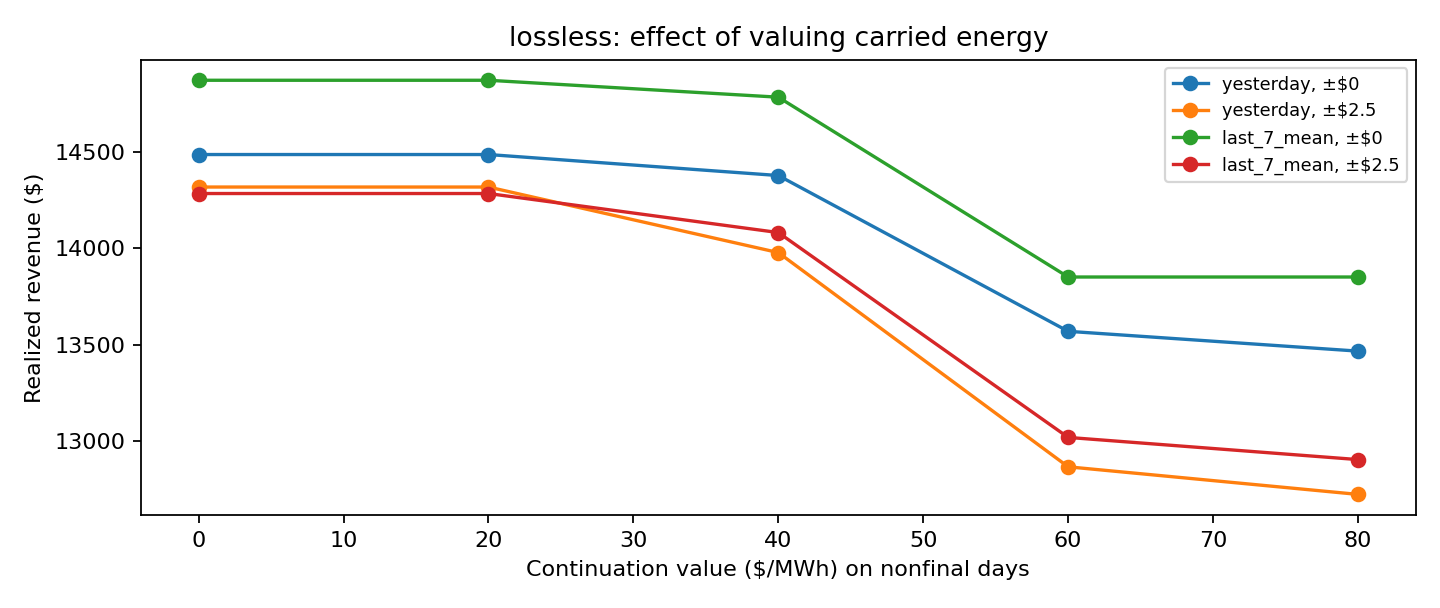

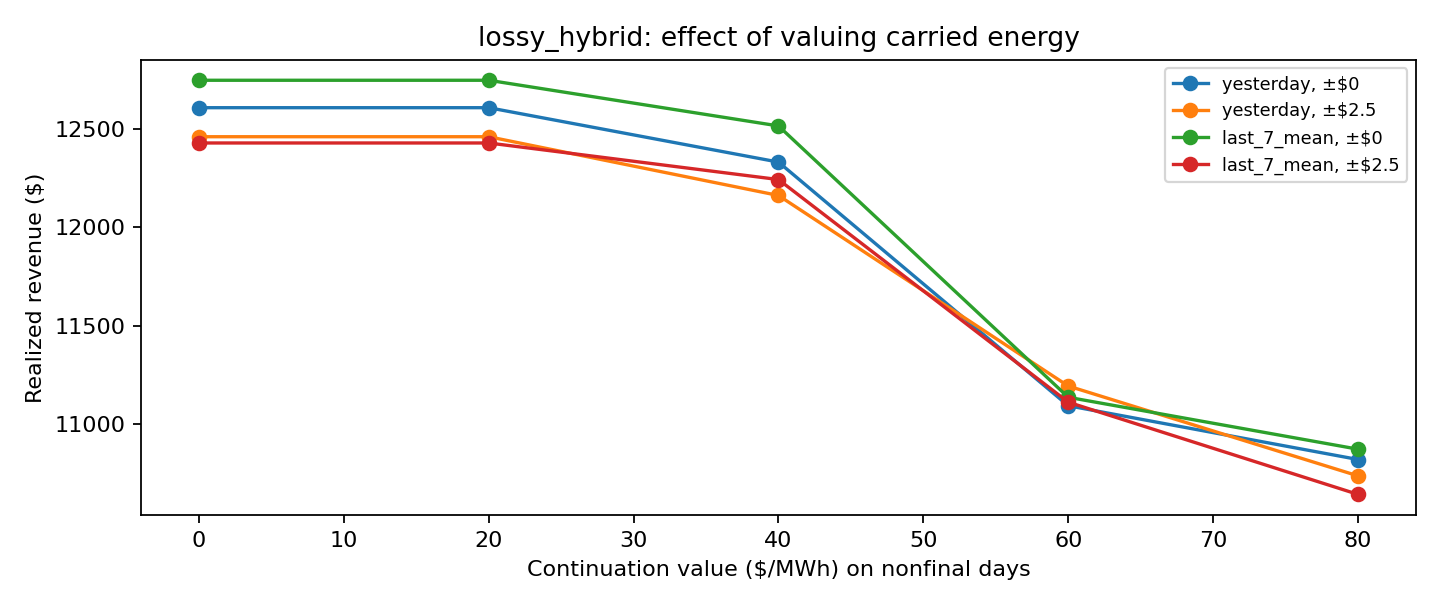

In [10]:
from IPython.display import display, Image
for kind in ('lossless','lossy_hybrid'):
    display(Image(filename=str(FIGURES/f'terminal_value_{kind}.png'),width=800))


## 10 · New: How well do the chosen uncertainty intervals cover actual prices?

The robust optimizer assumes that **every** hourly actual price falls in the interval `forecast ± radius`. For a historical diagnostic, we can check the fraction of hours that did so after the day completed. If coverage is low, the claimed worst-case revenue does **not** describe what would have happened on all historical days.

`±$2.50/MWh` is just an experimental radius. It is **not** the assignment's ±2.5 MWh battery charging limit. Coverage is measured on the released training data after scheduling; actual prices are never supplied as features to the scheduler.


In [11]:
from experiments import summarize_backtest
print('Price interval coverage, based on the historical backtest:')
for r in output['summary']:
    if r['kind']=='lossy_hybrid':
        print(f"  {r['predictor']:12} ±${r['uncertainty_usd_per_mwh']:4.1f}/MWh: "
              f"hourly coverage {100*r['empirical_hourly_coverage_fraction']:5.1f}% "
              f"(MAE ${r['avg_forecast_mae_usd_per_mwh']:.2f}/MWh)")


Price interval coverage, based on the historical backtest:
  last_7_mean  ±$ 0.0/MWh: hourly coverage   0.0% (MAE $9.03/MWh)
  last_7_mean  ±$ 2.5/MWh: hourly coverage  23.8% (MAE $9.03/MWh)
  last_7_mean  ±$10.0/MWh: hourly coverage  75.5% (MAE $9.03/MWh)
  yesterday    ±$ 0.0/MWh: hourly coverage   0.0% (MAE $6.60/MWh)
  yesterday    ±$ 2.5/MWh: hourly coverage  33.0% (MAE $6.60/MWh)
  yesterday    ±$10.0/MWh: hourly coverage  80.2% (MAE $6.60/MWh)


## 11 · Inspect saved figures and result files

These plots are generated from actual solver outputs. The last figure highlights an intentionally unrealistic relaxed SOC result, illustrating why that approach cannot be used blindly.

**Files to examine:** `results/backtest_summary.csv`, `results/backtest_daily.csv`, `results/smoke_trials.csv`, `results/run_manifest.json`, `results/unit_tests.txt`, and `results/figures/`.


 negative_price_dispatch.png


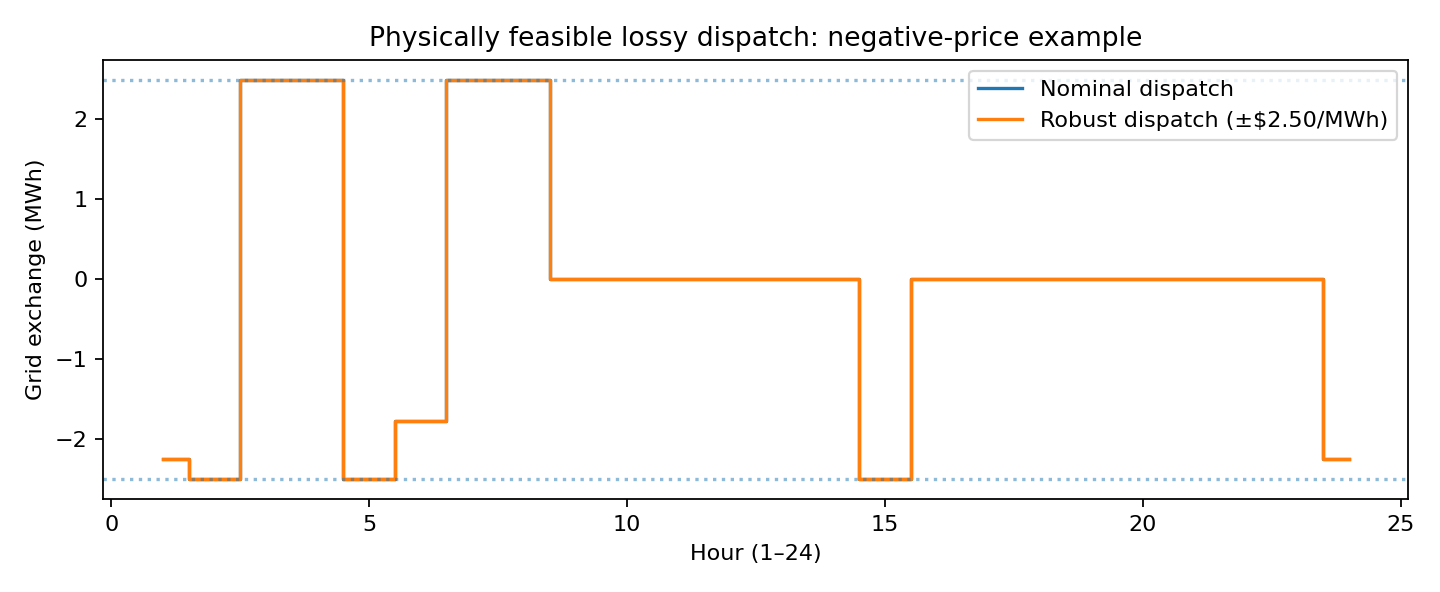


 negative_price_soc.png


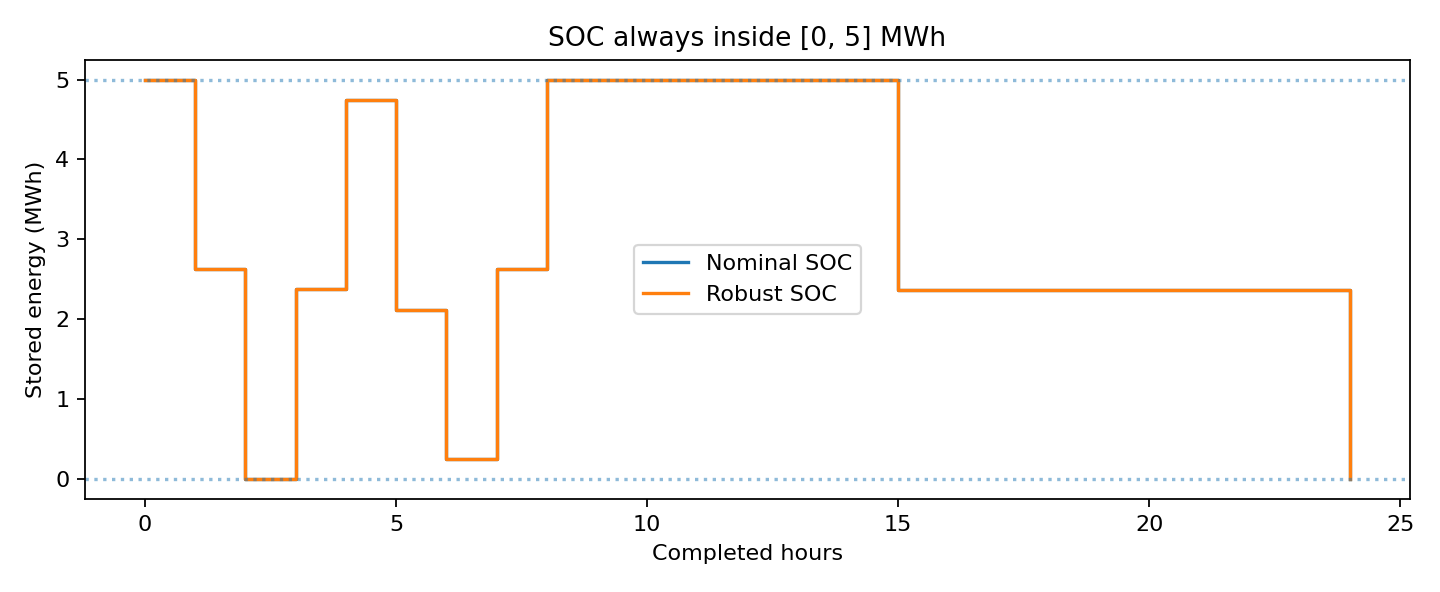


 cumulative_revenue.png


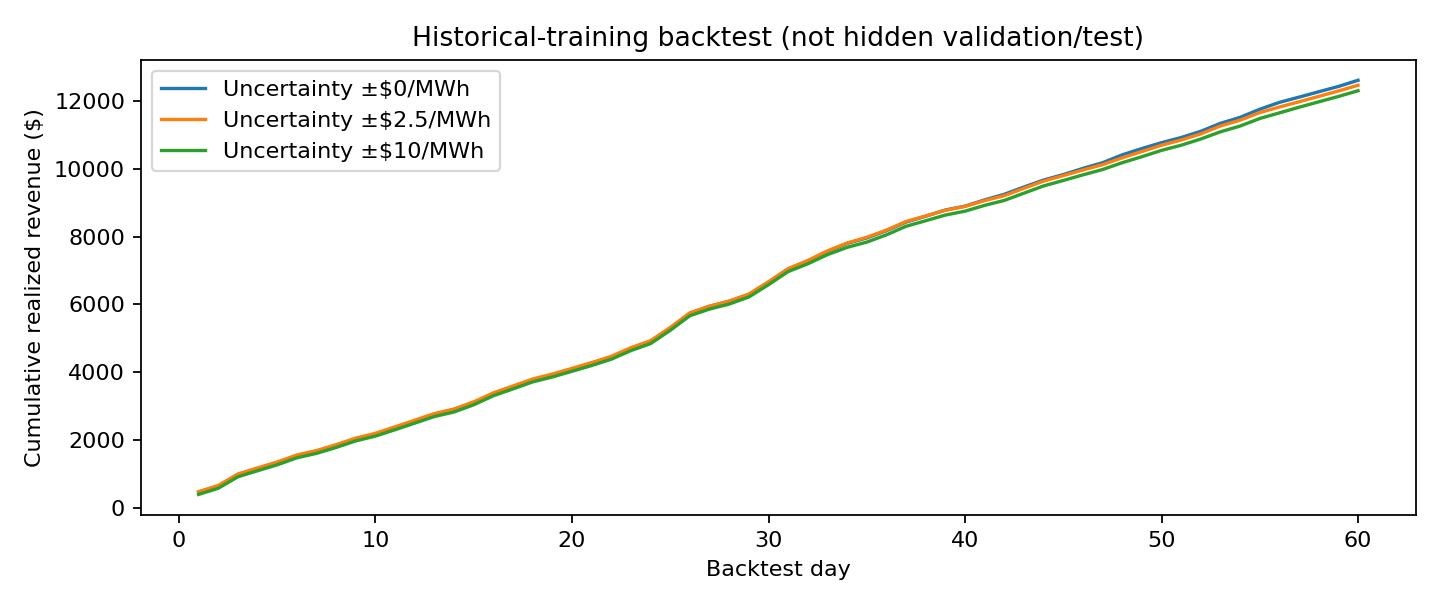


 relaxation_soc_mismatch.png


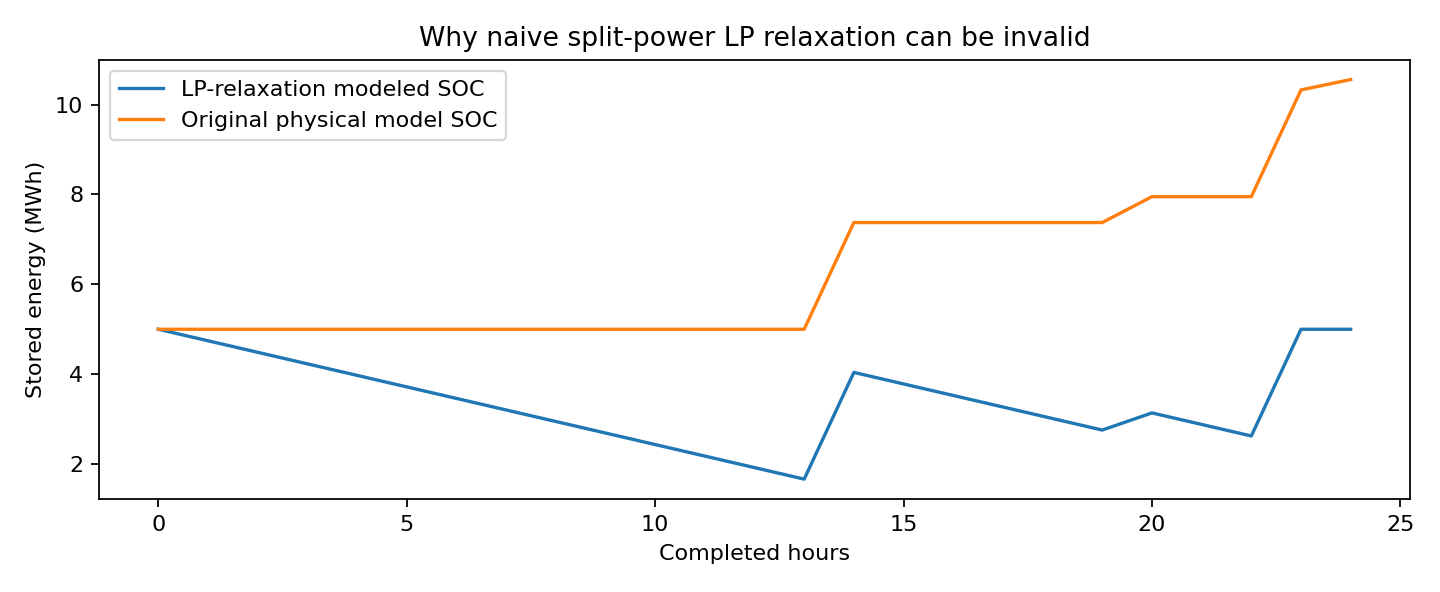

In [12]:
for filename in ['negative_price_dispatch.png','negative_price_soc.png',
                 'cumulative_revenue.png','relaxation_soc_mismatch.png']:
    print('\n',filename)
    display(Image(filename=str(FIGURES / filename),width=800))

## 12 · Your own custom experiment

Change `CUSTOM_PRICES` to **any list of exactly 24 hourly prices** (negative values are allowed), choose a starting SOC, and choose the assumed price-error radius. The optimizer automatically chooses the **exact convex LP if possible** or the **exact MILP otherwise**. The cells below do not use future actual prices.

Optional additional research: `terminal_value` in `optimizer.py` can place a dollar value on ending energy to discourage aggressive daily depletion, but is **zero by default**. There is no required final energy level in this assignment.

In [13]:
CUSTOM_PRICES = [15.0]*6 + [30.0]*6 + [85.0]*6 + [-12.0]*6
CUSTOM_SOC = 5.0
CUSTOM_RADIUS = 2.5

custom_prices=np.asarray(CUSTOM_PRICES,dtype=float)
custom,method=optimize_lossy_hybrid(custom_prices,CUSTOM_SOC,
                                   price_radius=CUSTOM_RADIUS,return_method=True)
custom_soc=stored_energy(custom,CUSTOM_SOC,lossy=True)
check_schedule(custom,CUSTOM_SOC,lossy=True)
print('Exact method:',method)
print('Forecast-price revenue: $',round(realized_revenue(custom_prices,custom),2))
print('Worst-case guaranteed revenue under assumed interval: $',
      round(worst_case_revenue(custom_prices,custom,CUSTOM_RADIUS),2))
print('Ending SOC: ',round(custom_soc[-1],5),'MWh')
print('\n Hour   Forecast $/MWh   Grid exchange (MWh)  End-of-hour SOC (MWh)')
for h in range(24):
    print(f' {h+1:>3}       {custom_prices[h]:>10.2f}            {custom[h]:>9.4f}                 {custom_soc[h+1]:>8.4f}')

Exact method: exact_soc_convex_lp
Forecast-price revenue: $ 466.91
Worst-case guaranteed revenue under assumed interval: $ 441.87
Ending SOC:  5.0 MWh

 Hour   Forecast $/MWh   Grid exchange (MWh)  End-of-hour SOC (MWh)
   1            15.00              -0.0000                   5.0000
   2            15.00               0.0000                   5.0000
   3            15.00               0.0000                   5.0000
   4            15.00               0.0000                   5.0000
   5            15.00               0.0000                   5.0000
   6            15.00              -0.0000                   5.0000
   7            30.00               0.0000                   5.0000
   8            30.00               0.0000                   5.0000
   9            30.00               0.0000                   5.0000
  10            30.00               0.0000                   5.0000
  11            30.00              -0.0000                   5.0000
  12            30.00           

## 13 · Interface for integration with the team

Supply `predicted_prices` as a 24-long vector of $/MWh for the trading day, computed from the permitted inputs only.

Call an optimizer with those prices and the current `initial_energy`, get a 24-long `p` with positive charging and negative discharging.

Run the official *lossless or lossy* physical state transition with `p`, carry the final state into the next day, and score revenue using realized prices **only after that day's schedule has been chosen**.

In [14]:
# Working mini integration example (replace placeholder forecast later):
predicted_prices = np.array([35.0]*12 + [75.0]*12)  # Placeholder; NOT real prices
current_energy = 5.0

p_lossless = optimize_lossless(predicted_prices,current_energy,price_radius=0.0)
p_lossy, selected = optimize_lossy_hybrid(predicted_prices,current_energy,
                                         price_radius=0.0,return_method=True)

print('Lossless p shape:',p_lossless.shape,
      'next-day SOC:',stored_energy(p_lossless,current_energy,lossy=False)[-1])
print('Lossy p shape:',p_lossy.shape,'method:',selected,
      'next-day SOC:',stored_energy(p_lossy,current_energy,lossy=True)[-1])

# Official function will likely return e.g. p_lossy.reshape(24,1) after
# computing predicted_prices from the nine permitted inputs.

Lossless p shape: (24,) next-day SOC: 0.0
Lossy p shape: (24,) method: exact_soc_convex_lp next-day SOC: 0.0


## 14 · Export a ZIP so we can improve the optimizer together

The last cell bundles the current result files, diagnostics, figures, notebook, and source code into **`ECE5280_RESULTS_TO_SHARE.zip`**.

**IMPORTANT:** After running all cells, **save your notebook** in Jupyter (Ctrl/Cmd+S), **then rerun this last cell**. This ensures the ZIP contains the latest notebook outputs. Upload that ZIP in the next chat; include any error messages and note which trial settings you used. You do not need to attach the full historical CSVs again.

The project permits AI-supported algorithm development and debugging with disclosure, but the final written report must be authored by your group.

In [16]:
results_zip = create_results_zip()
print('\nReady to share:',results_zip)

Results ZIP ready: ECE5280_RESULTS_TO_SHARE.zip (846,006 bytes)
Note: Save the notebook in Jupyter BEFORE creating ZIP to include its latest cell outputs.

Ready to share: /Users/aislinn/Downloads/ECE5280_Optimizer_v2/ECE5280_RESULTS_TO_SHARE.zip
